# Two L-method variants with a shared breakpoint

This experiment compares the two descriptions supplied by the user:

- **Two affine lines:** independently fit an affine head on $k=1,\ldots,q+1$ and an affine tail on $k=q+1,\ldots,K$.
- **Affine + constant:** independently fit the same affine head and a constant tail on $k=q+1,\ldots,K$.

Both use least squares and share the observed point at $k=q+1$. Sharing an observation does not impose equality of the fitted values there. No continuity, sign, or order penalty is imposed. The selected AR order is the candidate $q$, while $q+1$ is the estimated plateau onset. The candidate set is $q=1,\ldots,K-2$, ensuring at least two observations per segment. This makes order one admissible for both methods. The descriptions' range $q=1,\ldots,K$ would include empty or undefined tails.

The main score is the segment-size-weighted RMSE:
$$S(q)=\frac{q+1}{K+1}\operatorname{RMSE}_{\rm head}(q)+\frac{K-q}{K+1}\operatorname{RMSE}_{\rm tail}(q).$$
The shared point is counted in both segments, so their sizes sum to $K+1$. This is an adaptation of the weighting principle in [Salvador and Chan (2004), Section 3.2](https://cs.fit.edu/~pkc/papers/ictai04salvador.pdf); their original construction uses disjoint segments. It is selected in `L_method.py` by setting `weighted=True` and `common_breakpoint=True`.

Because “best fit” does not uniquely specify a score, a sensitivity comparison uses total squared error over the same two segments, also counting the shared point twice. Exact ties favor the smaller order. All results are comparisons on simulated data, not consistency guarantees.

In [1]:
import sys                                                                                          ### INFRASTRUCTURE
import json                                                                                         ### INFRASTRUCTURE
import hashlib                                                                                      ### INFRASTRUCTURE
from pathlib import Path                                                                            ### INFRASTRUCTURE
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt                                                                     ### PLOTTING
from threadpoolctl import threadpool_limits                                                         ### INFRASTRUCTURE

PROJECT_ROOT = next(root for root in (Path.cwd(), *Path.cwd().parents)                              ### INFRASTRUCTURE
                    if (root / "Code/Code_AR_processes/ar_tools/L_method.py").is_file())            ### INFRASTRUCTURE
if str(PROJECT_ROOT) not in sys.path:                                                               ### INFRASTRUCTURE
    sys.path.insert(0, str(PROJECT_ROOT))                                                           ### INFRASTRUCTURE
from Code.Code_AR_processes.ar_tools.functions import jones_ar_coefficients, simulate_uniform_ar
from Code.Code_AR_processes.ar_tools.descent import batched_geometric_width_curves
from Code.Code_AR_processes.ar_tools.L_method import l_method_selector

NAME = "ar_shared_breakpoint_l_methods"                                                             ### INFRASTRUCTURE
AR_DIR = PROJECT_ROOT / "Code/Code_AR_processes"                                                    ### INFRASTRUCTURE
CSV_DIR = AR_DIR / "outputs/csv" / NAME                                                             ### INFRASTRUCTURE
FIGURE_DIR = AR_DIR / "outputs/images" / NAME                                                       ### INFRASTRUCTURE
PDF_DIR = AR_DIR / "outputs/pdfs" / NAME                                                            ### INFRASTRUCTURE
for directory in (CSV_DIR, FIGURE_DIR, PDF_DIR):                                                    ### INFRASTRUCTURE
    directory.mkdir(parents=True, exist_ok=True)                                                    ### INFRASTRUCTURE
settings = {
    "replications_per_order": 50, "sample_size": 2000, "burnin": 1000,
    "half_width": 1.0, "k_values": list(range(1, 11)),
    "seeds": {"1": 20260813, "2": 20260814, "3": 20260816},
    "starts": 3, "iterations": 500, "initial_step": 0.2, "geometric_decay": 0.99,
    "width_source_hashes": {                                                                        ### INFRASTRUCTURE
        name: hashlib.sha256((AR_DIR / name).read_bytes()).hexdigest()                              ### INFRASTRUCTURE
        for name in ("ar_tools/functions.py", "ar_tools/descent.py")                                ### INFRASTRUCTURE
    },                                                                                              ### INFRASTRUCTURE
}
k_values = np.array(settings["k_values"])
print("50 processes per true order; T=2000; K=10; uniform innovations; shared breakpoint.")         ### REPORTING

50 processes per true order; T=2000; K=10; uniform innovations; shared breakpoint.


## Paired simulation

The seed families and width-optimizer settings match the preceding order-selection experiments in `ar_order_minimum_width.ipynb`: 50 independently parameterized AR processes per true order 1, 2, and 3; retained sample size 2,000; burn-in 1,000; uniform innovations on [-1,1]; three optimizer starts; 500 iterations; step sizes $0.2(0.99)^t$; and $k=1,\ldots,10$. Both methods use exactly the same estimated width curve for each replication. Cached curves are reused only if the settings and width-generator source hashes match.

In [2]:
configuration_path = CSV_DIR / "configuration.json"                                                 ### INFRASTRUCTURE
width_path = CSV_DIR / "width_curves.csv"                                                           ### INFRASTRUCTURE
use_cache = (configuration_path.is_file() and width_path.is_file()                                  ### INFRASTRUCTURE
             and json.loads(configuration_path.read_text()) == settings)                            ### INFRASTRUCTURE
expected_count = 3 * settings["replications_per_order"] * len(k_values)                             ### INFRASTRUCTURE
if use_cache:                                                                                       ### INFRASTRUCTURE
    width_curves = pd.read_csv(width_path)                                                          ### INFRASTRUCTURE
    use_cache = (len(width_curves) == expected_count                                                ### INFRASTRUCTURE
                 and not width_curves.duplicated(["true_order", "replication", "k"]).any())         ### INFRASTRUCTURE
if not use_cache:                                                                                   ### INFRASTRUCTURE
    rows = []
    started = perf_counter()
    with threadpool_limits(limits=1):                                                               ### INFRASTRUCTURE
        for true_order in (1, 2, 3):
            seed = settings["seeds"][str(true_order)]
            for replication in range(settings["replications_per_order"]):
                rng = np.random.default_rng(np.random.SeedSequence([seed, replication, 0]))
                phi = jones_ar_coefficients(true_order, rng=rng)
                series = simulate_uniform_ar(
                    phi, settings["sample_size"], settings["burnin"], settings["half_width"], rng=rng)
                _, widths, _ = batched_geometric_width_curves(
                    series, k_values, seed=seed, replication=replication,
                    starts=settings["starts"], iterations=settings["iterations"],
                    initial_step=settings["initial_step"], geometric_decay=settings["geometric_decay"])
                for k, width in zip(k_values, widths):
                    rows.append({"true_order": true_order, "replication": replication + 1,
                                 "k": int(k), "minimum_width": float(width),
                                 "coefficients": json.dumps(phi.tolist())})
                if (replication + 1) % 10 == 0:                                                     ### REPORTING
                    print(f"Completed {replication + 1}/50 AR({true_order}) curves", flush=True)    ### REPORTING
    width_curves = pd.DataFrame(rows)
    width_curves.to_csv(width_path, index=False)                                                    ### INFRASTRUCTURE
    configuration_path.write_text(json.dumps(settings, indent=2) + "\n")                            ### INFRASTRUCTURE
    print(f"Generated curves in {perf_counter() - started:.1f} seconds")                            ### REPORTING
else:                                                                                               ### INFRASTRUCTURE
    print("Reused all 150 cached width curves.")                                                    ### REPORTING
assert len(width_curves) == expected_count
assert np.isfinite(width_curves["minimum_width"]).all()

Completed 10/50 AR(1) curves
Completed 20/50 AR(1) curves
Completed 30/50 AR(1) curves
Completed 40/50 AR(1) curves
Completed 50/50 AR(1) curves
Completed 10/50 AR(2) curves
Completed 20/50 AR(2) curves
Completed 30/50 AR(2) curves
Completed 40/50 AR(2) curves
Completed 50/50 AR(2) curves
Completed 10/50 AR(3) curves
Completed 20/50 AR(3) curves
Completed 30/50 AR(3) curves
Completed 40/50 AR(3) curves
Completed 50/50 AR(3) curves
Generated curves in 47.6 seconds


In [3]:
methods = {"Two affine lines": "affine", "Affine + constant": "constant"}
selection_rows, candidate_frames = [], []
for (true_order, replication), curve in width_curves.groupby(["true_order", "replication"]):
    curve = curve.sort_values("k")
    for criterion in ("weighted_rmse", "squared_error"):
        for method, tail_model in methods.items():
            fit = l_method_selector(
                curve["minimum_width"].to_numpy(),
                weighted=criterion == "weighted_rmse", common_breakpoint=True,
                affine_affine=tail_model == "affine", squared_loss=True,
            )
            selection_rows.append({
                "true_order": int(true_order), "replication": int(replication),
                "method": method, "score_criterion": criterion,
                "selected_order": fit["selected_order"], "plateau_onset": fit["plateau_onset"],
                "score": fit["score"], "tail_slope": fit["right_slope"],
            })
            candidate_frames.append(fit["candidate_scores"].assign(
                true_order=true_order, replication=replication, method=method, score_criterion=criterion))
selections = pd.DataFrame(selection_rows)
selections.to_csv(CSV_DIR / "selections.csv", index=False)                                          ### INFRASTRUCTURE
pd.concat(candidate_frames, ignore_index=True).to_csv(                                              ### INFRASTRUCTURE
    CSV_DIR / "candidate_scores.csv", index=False,                                                  ### INFRASTRUCTURE
)                                                                                                   ### INFRASTRUCTURE
summary_rows = []
for (criterion, method, true_order), group in selections.groupby(["score_criterion", "method", "true_order"]):
    summary_rows.append({
        "score_criterion": criterion, "method": method, "true_order": int(true_order),
        "correct": int((group.selected_order == true_order).sum()),
        "under": int((group.selected_order < true_order).sum()),
        "over": int((group.selected_order > true_order).sum()), "total": len(group),
    })
summary = pd.DataFrame(summary_rows)
summary.to_csv(CSV_DIR / "summary.csv", index=False)                                                ### INFRASTRUCTURE
for criterion in ("weighted_rmse", "squared_error"):                                                ### REPORTING
    print(f"\n{criterion}: correct (under/over), out of 50")                                        ### REPORTING
    block = summary[summary.score_criterion == criterion].copy()                                    ### REPORTING
    block["entry"] = block.apply(lambda row: f"{row.correct}/50 ({row.under}/{row.over})", axis=1)  ### REPORTING
    print(                                                                                          ### REPORTING
        block.pivot(index="method", columns="true_order", values="entry")                           ### REPORTING
        .reindex(methods)                                                                           ### REPORTING
        .to_string()                                                                                ### REPORTING
    )                                                                                               ### REPORTING
paired = selections.pivot(index=["score_criterion", "true_order", "replication"],
                          columns="method", values="selected_order").reset_index()
paired.to_csv(CSV_DIR / "paired_selections.csv", index=False)                                       ### INFRASTRUCTURE
paired_rows = []
for (criterion, true_order), group in paired.groupby(["score_criterion", "true_order"]):
    a = group["Two affine lines"] == true_order
    b = group["Affine + constant"] == true_order
    paired_rows.append({"score_criterion": criterion, "true_order": int(true_order),
                        "both_correct": int((a & b).sum()), "only_two_affine_correct": int((a & ~b).sum()),
                        "only_affine_constant_correct": int((~a & b).sum()), "neither_correct": int((~a & ~b).sum())})
pd.DataFrame(paired_rows).to_csv(CSV_DIR / "paired_accuracy.csv", index=False)                      ### INFRASTRUCTURE


weighted_rmse: correct (under/over), out of 50
true_order                   1             2             3
method                                                    
Two affine lines   49/50 (0/1)  39/50 (11/0)  19/50 (30/1)
Affine + constant  49/50 (0/1)  40/50 (10/0)  19/50 (29/2)

squared_error: correct (under/over), out of 50
true_order                   1             2             3
method                                                    
Two affine lines   49/50 (0/1)  35/50 (15/0)  18/50 (32/0)
Affine + constant  49/50 (0/1)  37/50 (13/0)  18/50 (31/1)


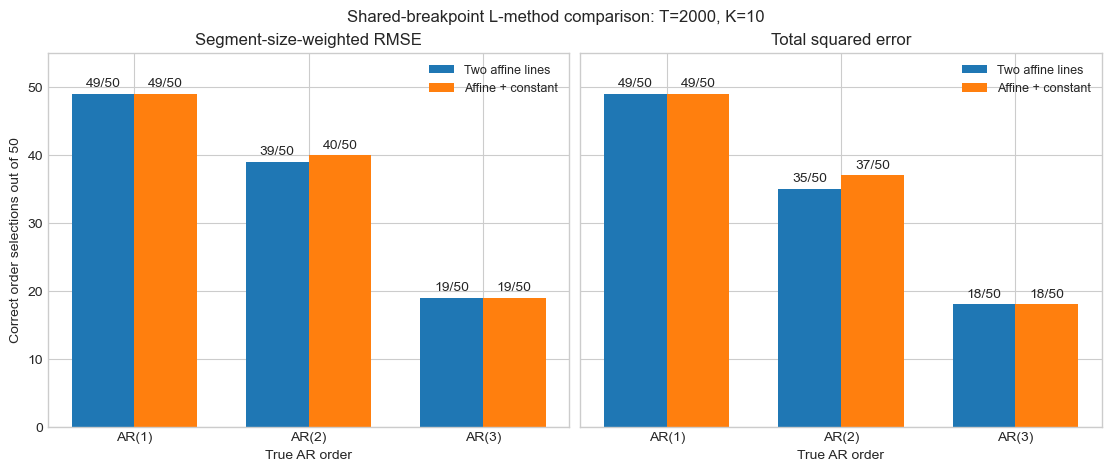

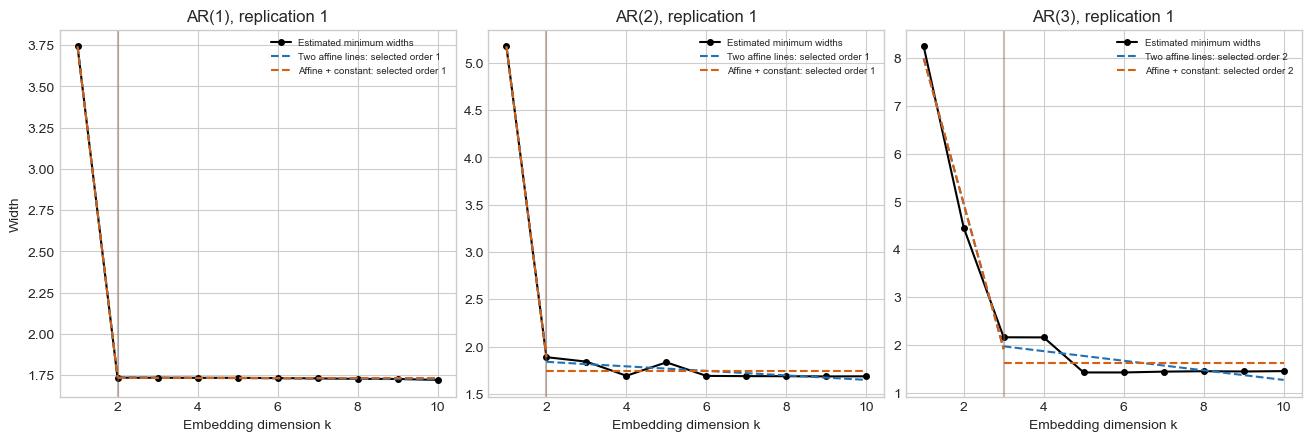

In [4]:
plt.style.use("seaborn-v0_8-whitegrid")                                                             ### PLOTTING
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained", sharey=True)                ### PLOTTING
for axis, criterion, title in zip(axes, ("weighted_rmse", "squared_error"),                         ### PLOTTING
                                  ("Segment-size-weighted RMSE", "Total squared error")):           ### PLOTTING
    x = np.arange(3)                                                                                ### PLOTTING
    for method_index, method in enumerate(methods):                                                 ### PLOTTING
        counts = (                                                                                  ### PLOTTING
            summary[                                                                                ### PLOTTING
                (summary.score_criterion == criterion)                                              ### PLOTTING
                & (summary.method == method)                                                        ### PLOTTING
            ]                                                                                       ### PLOTTING
            .sort_values("true_order")                                                              ### PLOTTING
            .correct.to_numpy()                                                                     ### PLOTTING
        )                                                                                           ### PLOTTING
        bars = axis.bar(x + (method_index - 0.5) * .36, counts, .36, label=method)                  ### PLOTTING
        axis.bar_label(bars, labels=[f"{count}/50" for count in counts], padding=3)                 ### PLOTTING
    axis.set(title=title, xlabel="True AR order", xticks=x,                                         ### PLOTTING
             xticklabels=["AR(1)", "AR(2)", "AR(3)"], ylim=(0, 55))                                 ### PLOTTING
    axis.legend(loc="upper right", fontsize=9)                                                      ### PLOTTING
axes[0].set_ylabel("Correct order selections out of 50")                                            ### PLOTTING
fig.suptitle("Shared-breakpoint L-method comparison: T=2000, K=10")                                 ### PLOTTING
fig.savefig(FIGURE_DIR / "accuracy.png", dpi=180)                                                   ### PLOTTING
fig.savefig(PDF_DIR / "accuracy.pdf")                                                               ### PLOTTING
plt.show()                                                                                          ### PLOTTING

# One example per true order, using the same observed curve for both fits.                          ### PLOTTING
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), layout="constrained")                             ### PLOTTING
for axis, true_order in zip(axes, (1, 2, 3)):                                                       ### PLOTTING
    curve = width_curves[                                                                           ### PLOTTING
        (width_curves.true_order == true_order)                                                     ### PLOTTING
        & (width_curves.replication == 1)                                                           ### PLOTTING
    ].sort_values("k")                                                                              ### PLOTTING
    axis.plot(                                                                                      ### PLOTTING
        curve.k, curve.minimum_width, "o-", color="black",                                          ### PLOTTING
        label="Estimated minimum widths", markersize=4,                                             ### PLOTTING
    )                                                                                               ### PLOTTING
    for method, tail_model in methods.items():                                                      ### PLOTTING
        fit = l_method_selector(                                                                    ### PLOTTING
            curve.minimum_width, weighted=True, common_breakpoint=True,                            ### PLOTTING
            affine_affine=tail_model == "affine", squared_loss=True,                          ### PLOTTING
        )                                                                                           ### PLOTTING
        color = "#2171b5" if tail_model == "affine" else "#d95f0e"                                  ### PLOTTING
        axis.plot(fit["left_k"], fit["left_fitted_values"], "--", color=color,                      ### PLOTTING
                  label=f"{method}: selected order {fit['selected_order']}")                        ### PLOTTING
        axis.plot(fit["right_k"], fit["right_fitted_values"], "--", color=color)                      ### PLOTTING
        axis.axvline(fit["plateau_onset"], color=color, alpha=.25)                                     ### PLOTTING
    axis.set(title=f"AR({true_order}), replication 1", xlabel="Embedding dimension k")              ### PLOTTING
    axis.legend(fontsize=7)                                                                         ### PLOTTING
axes[0].set_ylabel("Width")                                                                         ### PLOTTING
fig.savefig(FIGURE_DIR / "example_fits.png", dpi=180)                                               ### PLOTTING
fig.savefig(PDF_DIR / "example_fits.pdf")                                                           ### PLOTTING
plt.show()                                                                                          ### PLOTTING

## Results and interpretation

The following entries are correct selections out of 50, followed by (underselections/overselections).

| Main score: weighted RMSE | AR(1) | AR(2) | AR(3) | Correct total |
|---|---:|---:|---:|---:|
| Two affine lines | 49/50 (0/1) | 39/50 (11/0) | 19/50 (30/1) | 107/150 |
| Affine + constant | 49/50 (0/1) | 40/50 (10/0) | 19/50 (29/2) | 108/150 |

| Sensitivity score: total squared error | AR(1) | AR(2) | AR(3) | Correct total |
|---|---:|---:|---:|---:|
| Two affine lines | 49/50 (0/1) | 36/50 (14/0) | 18/50 (32/0) | 103/150 |
| Affine + constant | 49/50 (0/1) | 37/50 (13/0) | 18/50 (31/1) | 104/150 |

These tables are calculated in the cells above and exported to `outputs/csv/ar_shared_breakpoint_l_methods/summary.csv`. The paired correctness tables show that the affine-plus-constant method corrects exactly one AR(2) failure and introduces no new incorrect selections for either score. All AR(1) and AR(3) correctness outcomes agree, although some incorrect selected orders differ. The difference of one process gives little practical evidence of an advantage in this experiment.

My interpretation is that forcing the fitted tail to be horizontal has little effect on order recovery for these settings. Both methods frequently underselect AR(3). They share the same straight-line approximation before the candidate breakpoint; the experiment does not establish that this model-shape assumption is valid for every AR population width curve. This is an empirical observation on one fixed design and seed family, not a general performance guarantee.

This comparison uses the independent overlapping fits described by the user. The historical Table 2.1 instead used the continuous hinge model $c+s(q-k)_+$, $s\ge0$, fitted by LAD. Its results should not be substituted for this comparison.

## A schematic limitation of the plateau assumption

The following is an original constructed example, **not a verified AR population width curve**. It demonstrates that the bare condition of a constant tail after the true kink, with larger widths before it, is insufficient to guarantee either selector locates that kink. For $m=(9,6,2.6,1.6,1.6,1.6)$ the plateau starts at $k=4$, so the target order is $p=3$. Both methods choose $q=2$ under both scoring rules. An extra assumption about the pre-plateau shape or a separate correctness result would therefore be needed for a universal guarantee based solely on the plateau condition.


In [5]:
schematic_widths = np.array([9., 6., 2.6, 1.6, 1.6, 1.6])                                           ### REPORTING
for criterion in ("weighted_rmse", "squared_error"):                                                ### REPORTING
    for method, tail_model in methods.items():                                                      ### REPORTING
        fit = l_method_selector(                                                                    ### REPORTING
            schematic_widths, weighted=criterion == "weighted_rmse",                         ### REPORTING
            common_breakpoint=True, affine_affine=tail_model == "affine",                     ### REPORTING
            squared_loss=True,                                                                  ### REPORTING
        )                                                                                       ### REPORTING
        print(f"{criterion}, {method}: selected order {fit['selected_order']}; target order 3")     ### REPORTING


weighted_rmse, Two affine lines: selected order 2; target order 3
weighted_rmse, Affine + constant: selected order 2; target order 3
squared_error, Two affine lines: selected order 2; target order 3
squared_error, Affine + constant: selected order 2; target order 3
